# ChEMBL — Redes Neurais (MLP), preparação de dados e MLflow

**Objetivo:** aplicar **Redes Neurais** (`MLPClassifier`) à base multi-alvo de bioatividade do **ChEMBL**, prevendo se uma molécula é **ativa** contra cada uma das quatro proteínas-alvo. O trabalho **justifica as principais transformações de preparação de dados** e demonstra, pelas métricas, o efeito de cada uma, com todos os experimentos registrados no **MLflow**.

**Problema:** classificação binária por alvo. O rótulo vem do `pchembl_value` (potência, −log₁₀ da concentração molar): molécula **ativa** quando `pchembl_value ≥ 6,5` (limiar que deixa as quatro bases razoavelmente equilibradas).

**Alvos:** EGFR, BACE1, DRD2 e HDAC1 (modelos independentes — pouquíssimas moléculas aparecem em mais de um alvo).

**Abordagens comparadas (registradas no MLflow):**
- **Preparação dos dados:** política de tipo de medida (IC50 × IC50+Ki × todos), remoção de duplicatas e de SMILES inválidos, agregação por molécula (mediana), limiar de atividade, padronização dos atributos.
- **Featurização do SMILES:** fingerprint de Morgan/ECFP × descritores físico-químicos × combinação.
- **Hiperparâmetros da rede:** arquitetura (camadas/neurônios), ativação, regularização (`alpha`) e taxa de aprendizado.

> **Como executar:** ajuste `MODO` na primeira célula de código (`'completa'`, `'rapida'` ou `'smoke'`) e rode todas as células. Requer `rdkit` instalado (veja `requirements.txt`).

## Configuração, dependências e parâmetros do experimento

In [16]:
import os, json, time, shutil, zipfile, warnings
from datetime import datetime
from pathlib import Path

os.environ.setdefault('PYTHONWARNINGS', 'ignore')   # propaga aos workers do n_jobs=-1
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix)

import mlflow
import mlflow.sklearn

# RDKit e necessario para transformar o SMILES em atributos numericos.
# Instalacao (uma vez, no ambiente do projeto):  pip install rdkit
try:
    from rdkit import Chem
    from rdkit.Chem import AllChem, Descriptors
    from rdkit import RDLogger
    RDLogger.DisableLog('rdApp.*')
except ImportError as erro:
    raise ImportError(
        'RDKit nao encontrado. Instale com:  pip install rdkit\n'
        '(ou  conda install -c conda-forge rdkit). Detalhe: ' + str(erro))

SEED = 42
np.random.seed(SEED)

# ---------------------------------------------------------------------------
# Parametros globais do experimento (edite aqui)
# ---------------------------------------------------------------------------
# MODO controla o tamanho da grade de hiperparametros e a amostragem:
#   'completa' -> grade completa, base inteira (execucao mais longa)
#   'rapida'   -> grade reduzida, base inteira (bom para uma primeira passada)
#   'smoke'    -> grade minima + amostra pequena (apenas para testar o fluxo)
MODO = os.environ.get('CHEMBL_MODO', 'completa')

ALVOS = ['EGFR', 'BACE1', 'DRD2', 'HDAC1']   # as quatro proteinas da base
LIMIAR = 6.5                                  # pCHEMBL >= LIMIAR  ->  molecula "ativa"
POLITICA_TIPO = 'ic50_ki'                     # medidas mantidas na limpeza principal
FEATURIZACOES = ['morgan', 'descritores', 'combinado']
MORGAN_BITS = 2048
MORGAN_RAIO = 2

print('scikit-learn', sklearn.__version__, '| mlflow', mlflow.__version__)
print('MODO:', MODO, '| alvos:', ALVOS, '| limiar pCHEMBL:', LIMIAR)

scikit-learn 1.9.1 | mlflow 3.17.2
MODO: completa | alvos: ['EGFR', 'BACE1', 'DRD2', 'HDAC1'] | limiar pCHEMBL: 6.5


## Localização do projeto e MLflow

Mesma convenção dos notebooks anteriores: a raiz é a pasta que contém `bases/`, o MLflow grava no `mlflow.db` compartilhado e os artefatos vão para `docs/redes_neurais`.

In [17]:
def localiza_raiz(inicio=None):
    """Sobe a partir do diretorio atual ate encontrar bases/chembl_activities.csv."""
    env = os.environ.get('CHEMBL_RAIZ')
    if env:
        return Path(env).resolve()
    atual = Path(inicio or Path.cwd()).resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / 'bases' / 'chembl_activities.csv').exists():
            return pasta
    raise FileNotFoundError('Nao encontrei bases/chembl_activities.csv a partir de ' + str(atual))


RAIZ = localiza_raiz()
CSV = RAIZ / 'bases' / 'chembl_activities.csv'

# tudo que for gerado fica em docs/redes_neurais
PASTA_DOCS = RAIZ / 'docs' / 'redes_neurais'
PASTA_EXECUCAO = PASTA_DOCS / 'resultados' / f'execucao_{datetime.now():%Y%m%d_%H%M%S}'
PASTA_FIGURAS = PASTA_DOCS / 'figuras'
PASTA_EXECUCAO.mkdir(parents=True, exist_ok=True)
PASTA_FIGURAS.mkdir(parents=True, exist_ok=True)

MLFLOW_DB = (RAIZ / 'mlflow.db').resolve()
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DB}')
EXPERIMENTO = 'chembl_redes_neurais'
mlflow.set_experiment(EXPERIMENTO)


def salva_fig(fig, nome, dpi=150):
    """Salva a figura na pasta da execucao e copia para docs/redes_neurais/figuras."""
    destino = PASTA_EXECUCAO / nome
    fig.savefig(destino, dpi=dpi, bbox_inches='tight')
    shutil.copy(destino, PASTA_FIGURAS / nome)
    return destino


print('Base:', CSV)
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento:', EXPERIMENTO)
print('Pasta da execucao:', PASTA_EXECUCAO)

Base: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/bases/chembl_activities.csv
Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento: chembl_redes_neurais
Pasta da execucao: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/docs/redes_neurais/resultados/execucao_20261109_101057


## Entendimento da base

Cada linha é uma medição experimental da potência de uma molécula contra uma proteína. As colunas úteis são `protein` (alvo), `canonical_smiles` (estrutura da molécula) e `pchembl_value` (o alvo contínuo). Abaixo, a distribuição por alvo e do `pchembl_value`, com a linha do limiar de atividade.

Formato bruto: (58736, 14)


,protein,activity_id,molecule_chembl_id,canonical_smiles,target_chembl_id,assay_chembl_id,assay_type,standard_type,standard_relation,standard_value,standard_units,pchembl_value,data_validity_comment,potential_duplicate
0,EGFR,32260,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL203,CHEMBL674637,B,IC50,=,41.0,nM,7.39,NaN,0
1,EGFR,32267,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL203,CHEMBL674637,B,IC50,=,170.0,nM,6.77,NaN,0
2,EGFR,32680,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,CHEMBL203,CHEMBL677833,B,IC50,=,9300.0,nM,5.03,NaN,0
3,EGFR,32780,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL674643,B,IC50,=,96000.0,nM,4.02,NaN,0
4,EGFR,32781,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL675636,B,Ki,=,24000.0,nM,4.62,NaN,0



Registros por proteina-alvo:
protein
EGFR     19866
BACE1    15698
DRD2     12816
HDAC1    10356

Tipo de medida (standard_type):
standard_type
IC50    41511
Ki      14657
Kd       1175
EC50     1097
AC50      197
ED50       99

Unidades: <ArrowStringArray>
['nM']
Length: 1, dtype: str | relacao: <ArrowStringArray>
['=']
Length: 1, dtype: str | tipo de ensaio: <ArrowStringArray>
['B']
Length: 1, dtype: str

SMILES ausentes: 49
Marcados como potencial duplicata: 7328
Moleculas unicas: 37515

Distribuicao do pchembl_value por alvo:


,count,mean,std,min,25%,50%,75%,max
protein,,,,,,,,
BACE1,15698.0,6.88,1.21,2.35,6.01,6.98,7.77,10.96
DRD2,12816.0,6.84,1.11,4.00,6.07,6.71,7.52,11.00
EGFR,19866.0,7.12,1.33,4.00,6.16,7.19,8.10,11.00
HDAC1,10356.0,6.67,1.13,4.00,5.83,6.66,7.41,10.52


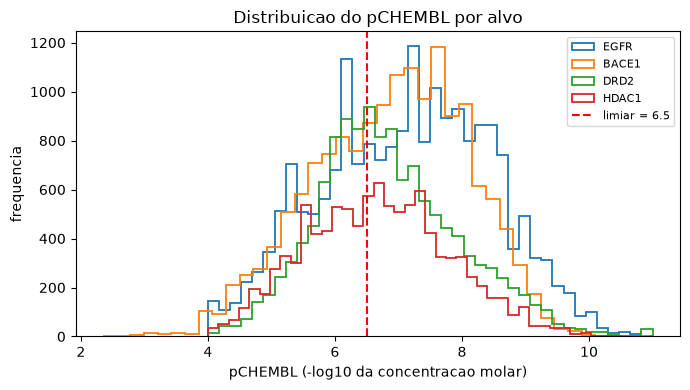

In [18]:
bruto = pd.read_csv(CSV)
print('Formato bruto:', bruto.shape)
display(bruto.head())

print('\nRegistros por proteina-alvo:')
print(bruto['protein'].value_counts().to_string())

print('\nTipo de medida (standard_type):')
print(bruto['standard_type'].value_counts().to_string())

print('\nUnidades:', bruto['standard_units'].unique(),
      '| relacao:', bruto['standard_relation'].unique(),
      '| tipo de ensaio:', bruto['assay_type'].unique())

print('\nSMILES ausentes:', int(bruto['canonical_smiles'].isna().sum()))
print('Marcados como potencial duplicata:', int((bruto['potential_duplicate'] == 1).sum()))
print('Moleculas unicas:', bruto['molecule_chembl_id'].nunique())

# pCHEMBL e o alvo: -log10 da concentracao molar; quanto maior, mais potente.
print('\nDistribuicao do pchembl_value por alvo:')
display(bruto.groupby('protein')['pchembl_value'].describe().round(2))

# histograma do alvo continuo, com a linha do limiar de atividade
fig, ax = plt.subplots(figsize=(7, 4))
for alvo in ALVOS:
    ax.hist(bruto.loc[bruto['protein'] == alvo, 'pchembl_value'],
            bins=40, histtype='step', label=alvo, linewidth=1.3)
ax.axvline(LIMIAR, color='red', linestyle='--', label=f'limiar = {LIMIAR}')
ax.set_xlabel('pCHEMBL (-log10 da concentracao molar)')
ax.set_ylabel('frequencia')
ax.set_title('Distribuicao do pCHEMBL por alvo')
ax.legend(fontsize=8)
fig.tight_layout()
salva_fig(fig, 'distribuicao_pchembl.png')
plt.show()

## Limpeza e preparação por alvo

A função abaixo concentra as transformações de preparação — cada uma com uma justificativa que entra no relatório. O ponto mais importante é a **agregação por molécula**: cerca de 30% dos pares alvo-molécula têm mais de uma medição, e deixá-las soltas colocaria a mesma molécula no treino e no teste (vazamento).

In [19]:
TIPOS_POR_POLITICA = {
    'ic50':    ['IC50'],
    'ic50_ki': ['IC50', 'Ki'],
    'todos':   None,   # mantem todos os standard_type
}


def prepara_alvo(df_bruto, alvo, politica=POLITICA_TIPO, limiar=LIMIAR, registra=True):
    """Limpa a base para uma proteina e devolve (dados, log das etapas).

    Etapas (todas justificaveis no relatorio):
      1. filtra a proteina;
      2. mantem apenas os tipos de medida da politica (IC50/Ki sao medidas de
         afinidade comparaveis; misturar com EC50/AC50 confunde potencia e eficacia);
      3. remove SMILES ausentes/invalidos e linhas marcadas como potencial duplicata;
      4. agrega medidas repetidas da mesma molecula pela mediana do pCHEMBL
         (evita a mesma molecula no treino e no teste -> sem vazamento);
      5. rotula ativa (1) / inativa (0) pelo limiar de pCHEMBL.
    """
    log = {'alvo': alvo, 'politica_tipo': politica, 'limiar': limiar}
    d = df_bruto[df_bruto['protein'] == alvo].copy()
    log['1_registros_do_alvo'] = len(d)

    tipos = TIPOS_POR_POLITICA[politica]
    if tipos is not None:
        d = d[d['standard_type'].isin(tipos)]
    log['2_apos_filtro_de_tipo'] = len(d)

    d = d[d['potential_duplicate'] != 1]
    d = d.dropna(subset=['canonical_smiles', 'pchembl_value'])
    d = d[d['canonical_smiles'].str.strip() != '']
    log['3_apos_remover_dup_e_smiles_vazios'] = len(d)

    # SMILES que o RDKit nao consegue interpretar sao descartados
    d['mol_valida'] = d['canonical_smiles'].apply(lambda s: Chem.MolFromSmiles(s) is not None)
    d = d[d['mol_valida']].drop(columns='mol_valida')
    log['4_apos_validar_smiles'] = len(d)

    # agregacao por molecula: mediana do pCHEMBL (um SMILES canonico por molecula)
    g = (d.groupby('molecule_chembl_id')
           .agg(canonical_smiles=('canonical_smiles', 'first'),
                pchembl=('pchembl_value', 'median'),
                n_medidas=('pchembl_value', 'size'))
           .reset_index())
    log['5_moleculas_unicas'] = len(g)

    g['y'] = (g['pchembl'] >= limiar).astype(int)
    log['ativos'] = int(g['y'].sum())
    log['inativos'] = int((g['y'] == 0).sum())
    log['proporcao_ativos'] = round(float(g['y'].mean()), 4)

    if registra:
        print(f"[{alvo}] {log['1_registros_do_alvo']} registros -> "
              f"{log['5_moleculas_unicas']} moleculas | "
              f"ativos {log['ativos']} ({log['proporcao_ativos']:.0%}) / "
              f"inativos {log['inativos']}")
    return g.reset_index(drop=True), log


# aplica a limpeza aos quatro alvos e mostra o efeito etapa a etapa
dados_alvo, logs_limpeza = {}, []
for alvo in ALVOS:
    g, log = prepara_alvo(bruto, alvo)
    dados_alvo[alvo] = g
    logs_limpeza.append(log)

tabela_limpeza = pd.DataFrame(logs_limpeza)
tabela_limpeza.to_csv(PASTA_EXECUCAO / 'limpeza_por_alvo.csv', index=False)
print('\nEfeito da limpeza (contagem por etapa):')
display(tabela_limpeza)

[EGFR] 19866 registros -> 10601 moleculas | ativos 6821 (64%) / inativos 3780
[BACE1] 15698 registros -> 9990 moleculas | ativos 6165 (62%) / inativos 3825
[DRD2] 12816 registros -> 8392 moleculas | ativos 4799 (57%) / inativos 3593
[HDAC1] 10356 registros -> 8003 moleculas | ativos 4292 (54%) / inativos 3711

Efeito da limpeza (contagem por etapa):


,alvo,politica_tipo,limiar,1_registros_do_alvo,2_apos_filtro_de_tipo,3_apos_remover_dup_e_smiles_vazios,4_apos_validar_smiles,5_moleculas_unicas,ativos,inativos,proporcao_ativos
0,EGFR,ic50_ki,6.5,19866,18661,16599,16599,10601,6821,3780,0.6434
1,BACE1,ic50_ki,6.5,15698,15237,12952,12952,9990,6165,3825,0.6171
2,DRD2,ic50_ki,6.5,12816,12038,10704,10704,8392,4799,3593,0.5719
3,HDAC1,ic50_ki,6.5,10356,10232,8840,8840,8003,4292,3711,0.5363


## Featurização: do SMILES para atributos numéricos

Uma rede neural não lê a estrutura química diretamente. Convertemos cada SMILES em atributos por dois caminhos — **fingerprint de Morgan/ECFP** (vetor binário de subestruturas) e **descritores físico-químicos** do RDKit — e também pela **combinação** dos dois. Esta é a transformação central deste trabalho e o principal eixo de comparação.

In [20]:
# --- fingerprint de Morgan (ECFP): vetor binario de subestruturas -----------
try:
    from rdkit.Chem import rdFingerprintGenerator
    _GEN_MORGAN = rdFingerprintGenerator.GetMorganGenerator(radius=MORGAN_RAIO, fpSize=MORGAN_BITS)

    def _morgan(mol):
        return np.asarray(_GEN_MORGAN.GetFingerprintAsNumPy(mol), dtype=np.float32)
except (ImportError, AttributeError):   # RDKit mais antigo
    from rdkit import DataStructs

    def _morgan(mol):
        bv = AllChem.GetMorganFingerprintAsBitVect(mol, MORGAN_RAIO, nBits=MORGAN_BITS)
        arr = np.zeros((MORGAN_BITS,), dtype=np.float32)
        DataStructs.ConvertToNumpyArray(bv, arr)
        return arr


# --- descritores fisico-quimicos do RDKit -----------------------------------
_NOMES_DESC = [nome for nome, _ in Descriptors.descList]
_FUNCS_DESC = [func for _, func in Descriptors.descList]


def _descritores(mol):
    vals = np.empty(len(_FUNCS_DESC), dtype=np.float64)
    for i, func in enumerate(_FUNCS_DESC):
        try:
            vals[i] = func(mol)
        except Exception:
            vals[i] = np.nan
    return vals


def featuriza(smiles):
    """Devolve (X_morgan, X_descritores, nomes_descritores) para uma lista de SMILES."""
    mols = [Chem.MolFromSmiles(s) for s in smiles]
    X_morgan = np.vstack([_morgan(m) for m in mols])
    X_desc = np.vstack([_descritores(m) for m in mols])
    X_desc = np.where(np.isfinite(X_desc), X_desc, np.nan)
    # mantem apenas descritores finitos em todas as moleculas (consistencia por alvo)
    ok = ~np.isnan(X_desc).any(axis=0)
    return X_morgan, X_desc[:, ok], [n for n, k in zip(_NOMES_DESC, ok) if k]


def matriz(target, feat, cache):
    """Monta a matriz de atributos para (alvo, featurizacao), usando cache."""
    Xm, Xd, nomes = cache[target]
    if feat == 'morgan':
        return Xm, [f'fp_{i}' for i in range(Xm.shape[1])]
    if feat == 'descritores':
        return Xd, list(nomes)
    return np.hstack([Xm, Xd]), [f'fp_{i}' for i in range(Xm.shape[1])] + list(nomes)


# calcula as featurizacoes uma vez por alvo (reaproveitadas nas 3 representacoes)
if MODO == 'smoke':
    for a in ALVOS:
        dados_alvo[a] = dados_alvo[a].sample(min(400, len(dados_alvo[a])),
                                             random_state=SEED).reset_index(drop=True)

FEATS_CACHE = {}
for alvo in ALVOS:
    t0 = time.time()
    Xm, Xd, nomes = featuriza(dados_alvo[alvo]['canonical_smiles'].tolist())
    FEATS_CACHE[alvo] = (Xm, Xd, nomes)
    print(f'[{alvo}] morgan {Xm.shape} | descritores {Xd.shape} '
          f'| {time.time() - t0:.1f} s')

[EGFR] morgan (10601, 2048) | descritores (10601, 205) | 57.2 s
[BACE1] morgan (9990, 2048) | descritores (9990, 205) | 52.8 s
[DRD2] morgan (8392, 2048) | descritores (8392, 205) | 44.2 s
[HDAC1] morgan (8003, 2048) | descritores (8003, 205) | 39.8 s


## Métricas e grade de hiperparâmetros

Métricas por classe, matriz de confusão, IC 95% do F1 (bootstrap) e, como a rede fornece probabilidade, **ROC-AUC** e **PR-AUC**. A grade de hiperparâmetros da rede varia arquitetura, ativação, regularização e taxa de aprendizado; o tamanho é controlado por `MODO`.

In [21]:
def bootstrap_f1(y_true, pred, n=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    y_true, pred = np.asarray(y_true), np.asarray(pred)
    vals = [f1_score(y_true[idx], pred[idx], zero_division=0)
            for idx in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])


def metricas_teste(y_true, pred, proba=None):
    """Metricas das duas classes, matriz de confusao, IC95 do F1 e, se houver
    probabilidade, ROC-AUC e PR-AUC (area sob a curva precisao-revocacao)."""
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    lo, hi = bootstrap_f1(y_true, pred)
    m = {
        'Acuracia': float(accuracy_score(y_true, pred)),
        'Precisao_c0': float(precision_score(y_true, pred, pos_label=0, zero_division=0)),
        'Recall_c0': float(recall_score(y_true, pred, pos_label=0, zero_division=0)),
        'F1_c0': float(f1_score(y_true, pred, pos_label=0, zero_division=0)),
        'Precisao_c1': float(precision_score(y_true, pred, pos_label=1, zero_division=0)),
        'Recall_c1': float(recall_score(y_true, pred, pos_label=1, zero_division=0)),
        'F1_c1': float(f1_score(y_true, pred, pos_label=1, zero_division=0)),
        'F1_macro': float(f1_score(y_true, pred, average='macro', zero_division=0)),
        'F1_c1_IC95_inf': float(lo), 'F1_c1_IC95_sup': float(hi),
        'ROC_AUC': float('nan'), 'PR_AUC': float('nan'),
        'TN': float(tn), 'FP': float(fp), 'FN': float(fn), 'TP': float(tp),
    }
    if proba is not None:
        m['ROC_AUC'] = float(roc_auc_score(y_true, proba))
        m['PR_AUC'] = float(average_precision_score(y_true, proba))
    return m


# ---------------------------------------------------------------------------
# Grade de hiperparametros da rede neural (MLPClassifier)
# ---------------------------------------------------------------------------
if MODO == 'completa':
    GRADE = {
        'mlp__hidden_layer_sizes': [(128,), (256, 128), (128, 64)],
        'mlp__activation': ['relu', 'tanh'],
        'mlp__alpha': [1e-4, 1e-3],
        'mlp__learning_rate_init': [1e-3, 5e-4],
    }
    N_SPLITS = 5
elif MODO == 'rapida':
    GRADE = {
        'mlp__hidden_layer_sizes': [(128,), (256, 128)],
        'mlp__activation': ['relu'],
        'mlp__alpha': [1e-4, 1e-3],
        'mlp__learning_rate_init': [1e-3],
    }
    N_SPLITS = 5
else:  # smoke
    GRADE = {
        'mlp__hidden_layer_sizes': [(64,)],
        'mlp__alpha': [1e-3],
    }
    N_SPLITS = 3

SCORING = {'f1': 'f1', 'acuracia': 'accuracy', 'precisao': 'precision',
           'recall': 'recall', 'roc_auc': 'roc_auc'}
N_COMBINACOES = len(ParameterGrid(GRADE))
MAX_ITER = 60 if MODO == 'smoke' else 300


def novo_mlp():
    return MLPClassifier(max_iter=MAX_ITER, early_stopping=True, n_iter_no_change=15,
                         validation_fraction=0.1, random_state=SEED)


def pipeline_mlp(escala=True):
    passos = []
    if escala:
        passos.append(('sc', StandardScaler()))
    passos.append(('mlp', novo_mlp()))
    return Pipeline(passos)


print('Grade MLP:', N_COMBINACOES, 'combinacoes |', N_SPLITS, 'folds |',
      'fits por (alvo,featurizacao):', N_COMBINACOES * N_SPLITS)
print('Total estimado de buscas:', len(ALVOS) * len(FEATURIZACOES),
      '(alvo x featurizacao)')

Grade MLP: 24 combinacoes | 5 folds | fits por (alvo,featurizacao): 120
Total estimado de buscas: 12 (alvo x featurizacao)


## Busca de hiperparâmetros por alvo e featurização

Para cada combinação (alvo × featurização), um `GridSearchCV` com validação cruzada estratificada seleciona a rede pelo F1 da classe 1; as métricas de teste são calculadas no conjunto reservado (20%) e registradas no MLflow.

In [22]:
# split estratificado 80/20 por alvo (fixo para todas as featurizacoes do alvo)
SPLITS = {}
for alvo in ALVOS:
    y = dados_alvo[alvo]['y'].values
    idx = np.arange(len(y))
    itr, ite = train_test_split(idx, test_size=0.2, random_state=SEED, stratify=y)
    SPLITS[alvo] = (itr, ite)

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

linhas, melhores = [], {}
for alvo in ALVOS:
    itr, ite = SPLITS[alvo]
    y = dados_alvo[alvo]['y'].values
    y_tr, y_te = y[itr], y[ite]
    for feat in FEATURIZACOES:
        X, _ = matriz(alvo, feat, FEATS_CACHE)
        X_tr, X_te = X[itr], X[ite]
        busca = GridSearchCV(pipeline_mlp(), GRADE, cv=cv, scoring=SCORING, refit='f1',
                             n_jobs=-1, error_score='raise')
        with mlflow.start_run(run_name=f'mlp_{alvo}_{feat}') as run:
            t0 = time.time()
            busca.fit(X_tr, y_tr)
            dur = time.time() - t0
            i = busca.best_index_
            proba = busca.predict_proba(X_te)[:, 1]
            pred = (proba >= 0.5).astype(int)
            met = metricas_teste(y_te, pred, proba)

            mlflow.log_params({'alvo': alvo, 'featurizacao': feat,
                               'n_atributos': X.shape[1], 'limiar_pchembl': LIMIAR,
                               'politica_tipo': POLITICA_TIPO,
                               'n_combinacoes': N_COMBINACOES,
                               'n_treino': len(itr), 'n_teste': len(ite)})
            mlflow.log_params({k: str(v) for k, v in busca.best_params_.items()})
            mlflow.log_metric('tempo_busca_s', float(dur))
            mlflow.log_metric('f1_cv', float(busca.best_score_))
            mlflow.log_metric('f1_cv_std', float(busca.cv_results_['std_test_f1'][i]))
            mlflow.log_metric('roc_auc_cv', float(busca.cv_results_['mean_test_roc_auc'][i]))
            mlflow.log_metrics({k: float(v) for k, v in met.items()})

        linhas.append({'Alvo': alvo, 'Featurizacao': feat,
                       'N_atributos': X.shape[1],
                       'F1_CV': float(busca.best_score_),
                       'ROC_AUC_CV': float(busca.cv_results_['mean_test_roc_auc'][i]),
                       'Tempo_s': float(dur), **met})
        melhores[(alvo, feat)] = busca
        print(f'[{alvo} | {feat}] F1_CV {busca.best_score_:.4f} | '
              f'F1_c1 {met["F1_c1"]:.4f} | ROC-AUC {met["ROC_AUC"]:.4f} | '
              f'{dur:.0f} s | {busca.best_params_}')

comparacao = pd.DataFrame(linhas)
comparacao.to_csv(PASTA_EXECUCAO / 'comparacao_featurizacoes.csv', index=False)
print('\nResultado por alvo e featurizacao (ordenado por F1 da classe 1):')
display(comparacao.sort_values(['Alvo', 'F1_c1'], ascending=[True, False])
        .round(4).reset_index(drop=True))

[EGFR | morgan] F1_CV 0.8816 | F1_c1 0.8808 | ROC-AUC 0.9000 | 93 s | {'mlp__activation': 'relu', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (256, 128), 'mlp__learning_rate_init': 0.001}
[EGFR | descritores] F1_CV 0.8725 | F1_c1 0.8713 | ROC-AUC 0.8860 | 38 s | {'mlp__activation': 'tanh', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (128,), 'mlp__learning_rate_init': 0.001}
[EGFR | combinado] F1_CV 0.8843 | F1_c1 0.8840 | ROC-AUC 0.9023 | 228 s | {'mlp__activation': 'relu', 'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (256, 128), 'mlp__learning_rate_init': 0.001}
[BACE1 | morgan] F1_CV 0.8712 | F1_c1 0.8598 | ROC-AUC 0.8986 | 80 s | {'mlp__activation': 'relu', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (256, 128), 'mlp__learning_rate_init': 0.001}
[BACE1 | descritores] F1_CV 0.8632 | F1_c1 0.8693 | ROC-AUC 0.8934 | 45 s | {'mlp__activation': 'tanh', 'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (128,), 'mlp__learning_rate_init': 0.001}
[BACE1 | combinado] F1_CV 0.87

,Alvo,Featurizacao,N_atributos,F1_CV,ROC_AUC_CV,Tempo_s,Acuracia,Precisao_c0,Recall_c0,F1_c0,...,F1_c1,F1_macro,F1_c1_IC95_inf,F1_c1_IC95_sup,ROC_AUC,PR_AUC,TN,FP,FN,TP
0,BACE1,descritores,205,0.8632,0.8917,44.6922,0.8343,0.8109,0.7399,0.7738,...,0.8693,0.8215,0.8549,0.8837,0.8934,0.9154,566.0,199.0,132.0,1101.0
1,BACE1,combinado,2253,0.8714,0.9030,211.7286,0.8323,0.7921,0.7621,0.7768,...,0.8657,0.8213,0.8522,0.8804,0.9049,0.9300,583.0,182.0,153.0,1080.0
2,BACE1,morgan,2048,0.8712,0.9003,79.6133,0.8253,0.7803,0.7569,0.7684,...,0.8598,0.8141,0.8455,0.8755,0.8986,0.9258,579.0,186.0,163.0,1070.0
3,DRD2,combinado,2253,0.8140,0.8602,199.6452,0.8011,0.7670,0.7691,0.7681,...,0.8259,0.7970,0.8060,0.8443,0.8744,0.8999,553.0,166.0,168.0,792.0
4,DRD2,morgan,2048,0.8126,0.8566,83.4799,0.7957,0.7798,0.7288,0.7534,...,0.8256,0.7895,0.8068,0.8437,0.8678,0.8908,524.0,195.0,148.0,812.0
5,DRD2,descritores,205,0.8080,0.8487,46.5435,0.7898,0.7549,0.7538,0.7543,...,0.8162,0.7853,0.7966,0.8360,0.8627,0.8909,542.0,177.0,176.0,784.0
6,EGFR,combinado,2253,0.8843,0.9082,227.6110,0.8496,0.7965,0.7765,0.7863,...,0.8840,0.8351,0.8712,0.8959,0.9023,0.9331,587.0,169.0,150.0,1215.0
7,EGFR,morgan,2048,0.8816,0.9047,92.8751,0.8425,0.8085,0.7315,0.7681,...,0.8808,0.8244,0.8677,0.8935,0.9000,0.9308,553.0,203.0,131.0,1234.0
8,EGFR,descritores,205,0.8725,0.8920,37.8166,0.8289,0.7955,0.6997,0.7445,...,0.8713,0.8079,0.8578,0.8845,0.8860,0.9277,529.0,227.0,136.0,1229.0
9,HDAC1,morgan,2048,0.8203,0.8833,96.5559,0.8282,0.8284,0.7938,0.8107,...,0.8428,0.8268,0.8230,0.8599,0.8996,0.9147,589.0,153.0,122.0,737.0


## Referência ingênua (classe majoritária)

Um `DummyClassifier` que prevê sempre a classe majoritária, por alvo, serve de piso de comparação.

In [23]:
# referencia ingenua: preve sempre a classe majoritaria (por alvo)
linhas_base = []
for alvo in ALVOS:
    itr, ite = SPLITS[alvo]
    y = dados_alvo[alvo]['y'].values
    X, _ = matriz(alvo, 'morgan', FEATS_CACHE)
    dummy = DummyClassifier(strategy='most_frequent')
    with mlflow.start_run(run_name=f'baseline_{alvo}'):
        dummy.fit(X[itr], y[itr])
        pred = dummy.predict(X[ite])
        met = metricas_teste(y[ite], pred)
        mlflow.log_params({'alvo': alvo, 'modelo': 'DummyClassifier(most_frequent)'})
        mlflow.log_metrics({k: float(v) for k, v in met.items()})
    linhas_base.append({'Alvo': alvo, **met})

baseline = pd.DataFrame(linhas_base)
baseline.to_csv(PASTA_EXECUCAO / 'baseline_por_alvo.csv', index=False)
print('Referencia (classe majoritaria) por alvo:')
display(baseline[['Alvo', 'Acuracia', 'F1_c1', 'F1_macro']].round(4))

Referencia (classe majoritaria) por alvo:


,Alvo,Acuracia,F1_c1,F1_macro
0,EGFR,0.6436,0.7831,0.3916
1,BACE1,0.6171,0.7632,0.3816
2,DRD2,0.5718,0.7275,0.3638
3,HDAC1,0.5365,0.6984,0.3492


## Abordagem de dados: sensibilidade ao limiar de atividade

O limiar que separa ativa/inativa é uma decisão de preparação. Aqui ele varia (6,0, 6,5 e 7,0) **mantendo as mesmas moléculas de treino e teste** — só o rótulo muda — para isolar o efeito do limiar.

In [24]:
# featurizacao de referencia: a de melhor F1_CV medio entre os alvos
FEAT_REF = (comparacao.groupby('Featurizacao')['F1_CV'].mean().idxmax())
print('Featurizacao de referencia (melhor F1_CV medio):', FEAT_REF)


def melhores_params_mlp(busca):
    return {k.replace('mlp__', ''): v for k, v in busca.best_params_.items()}


# Sensibilidade ao limiar de atividade: mantem as mesmas moleculas de treino/teste
# (sem vazamento) e apenas re-rotula ativa/inativa em cada limiar.
linhas_lim = []
with mlflow.start_run(run_name='sensibilidade_limiar'):
    for alvo in ALVOS:
        itr, ite = SPLITS[alvo]
        X, _ = matriz(alvo, FEAT_REF, FEATS_CACHE)
        pchembl = dados_alvo[alvo]['pchembl'].values
        params = melhores_params_mlp(melhores[(alvo, FEAT_REF)])
        for limiar in [6.0, 6.5, 7.0]:
            y = (pchembl >= limiar).astype(int)
            if len(np.unique(y[itr])) < 2:
                continue
            pipe = pipeline_mlp()
            pipe.named_steps['mlp'].set_params(**params)
            pipe.fit(X[itr], y[itr])
            proba = pipe.predict_proba(X[ite])[:, 1]
            met = metricas_teste(y[ite], (proba >= 0.5).astype(int), proba)
            with mlflow.start_run(run_name=f'{alvo}_limiar_{limiar}', nested=True):
                mlflow.log_params({'alvo': alvo, 'featurizacao': FEAT_REF, 'limiar': limiar})
                mlflow.log_metrics({k: float(v) for k, v in met.items()})
            linhas_lim.append({'Alvo': alvo, 'Limiar': limiar,
                               'Prop_ativos': float(y.mean()), **met})

sensibilidade_limiar = pd.DataFrame(linhas_lim)
sensibilidade_limiar.to_csv(PASTA_EXECUCAO / 'sensibilidade_limiar.csv', index=False)
print('Efeito do limiar de atividade (featurizacao de referencia):')
display(sensibilidade_limiar[['Alvo', 'Limiar', 'Prop_ativos',
                              'F1_c1', 'F1_macro', 'ROC_AUC']].round(4))

Featurizacao de referencia (melhor F1_CV medio): combinado
Efeito do limiar de atividade (featurizacao de referencia):


,Alvo,Limiar,Prop_ativos,F1_c1,F1_macro,ROC_AUC
0,EGFR,6.0,0.7623,0.9302,0.8435,0.9290
1,EGFR,6.5,0.6434,0.8840,0.8351,0.9023
2,EGFR,7.0,0.5159,0.8323,0.8242,0.9032
3,BACE1,6.0,0.7342,0.9087,0.8165,0.9103
4,BACE1,6.5,0.6171,0.8657,0.8213,0.9049
5,BACE1,7.0,0.4782,0.8190,0.8223,0.8912
6,DRD2,6.0,0.7822,0.8979,0.7497,0.8419
7,DRD2,6.5,0.5719,0.8259,0.7970,0.8744
8,DRD2,7.0,0.3771,0.7663,0.8162,0.8940
9,HDAC1,6.0,0.7009,0.8900,0.8124,0.8959


## Abordagem de dados: efeito da padronização

Redes neurais são sensíveis à escala dos atributos. Os descritores físico-químicos têm ordens de grandeza muito diferentes; o fingerprint já é binário. Comparamos com e sem `StandardScaler`, com os mesmos hiperparâmetros.

In [25]:
# Efeito da padronizacao dos atributos: com e sem StandardScaler, mesmos
# hiperparametros. Redes neurais sao sensiveis a escala; descritores fisico-quimicos
# tem ordens de grandeza muito diferentes, enquanto o fingerprint ja e binario.
linhas_esc = []
with mlflow.start_run(run_name='efeito_escala'):
    for alvo in ALVOS:
        itr, ite = SPLITS[alvo]
        y = dados_alvo[alvo]['y'].values
        X, _ = matriz(alvo, FEAT_REF, FEATS_CACHE)
        params = melhores_params_mlp(melhores[(alvo, FEAT_REF)])
        for escala in [True, False]:
            pipe = pipeline_mlp(escala=escala)
            pipe.named_steps['mlp'].set_params(**params)
            pipe.fit(X[itr], y[itr])
            proba = pipe.predict_proba(X[ite])[:, 1]
            met = metricas_teste(y[ite], (proba >= 0.5).astype(int), proba)
            with mlflow.start_run(run_name=f'{alvo}_escala_{escala}', nested=True):
                mlflow.log_params({'alvo': alvo, 'featurizacao': FEAT_REF,
                                   'padronizacao': escala})
                mlflow.log_metrics({k: float(v) for k, v in met.items()})
            linhas_esc.append({'Alvo': alvo, 'Padronizacao': escala,
                               'F1_c1': met['F1_c1'], 'ROC_AUC': met['ROC_AUC'],
                               'Acuracia': met['Acuracia']})

efeito_escala = pd.DataFrame(linhas_esc)
efeito_escala.to_csv(PASTA_EXECUCAO / 'efeito_escala.csv', index=False)
print('Efeito da padronizacao (featurizacao de referencia):')
display(efeito_escala.pivot(index='Alvo', columns='Padronizacao',
                            values=['F1_c1', 'ROC_AUC']).round(4))

Efeito da padronizacao (featurizacao de referencia):


F1_c1         ROC_AUC        
Padronizacao   False   True    False   True 
Alvo                                        
BACE1         0.0000  0.8657  0.4809  0.9049
DRD2          0.7224  0.8259  0.5126  0.8744
EGFR          0.7864  0.8840  0.5115  0.9023
HDAC1         0.7014  0.8424  0.5090  0.9120

## Abordagem de dados: política de tipo de medida

Misturar IC50, Ki, EC50 etc. junta potências de naturezas distintas. Aqui comparamos manter só IC50, IC50+Ki (padrão adotado) e todos os tipos, observando o efeito no tamanho da base e nas métricas (no alvo de referência, para limitar o custo).

In [26]:
# Efeito da politica de tipo de medida (standard_type) sobre a base e o modelo.
# Feito no alvo de referencia para limitar o custo (re-featurizacao a cada politica).
ALVO_POLITICA = ALVOS[0]
linhas_pol = []
with mlflow.start_run(run_name='politica_medida'):
    for politica in ['ic50', 'ic50_ki', 'todos']:
        g, log = prepara_alvo(bruto, ALVO_POLITICA, politica=politica, registra=False)
        if MODO == 'smoke':
            g = g.sample(min(400, len(g)), random_state=SEED).reset_index(drop=True)
        Xm, Xd, _ = featuriza(g['canonical_smiles'].tolist())
        X = Xm if FEAT_REF == 'morgan' else (Xd if FEAT_REF == 'descritores'
                                             else np.hstack([Xm, Xd]))
        y = g['y'].values
        itr, ite = train_test_split(np.arange(len(y)), test_size=0.2,
                                    random_state=SEED, stratify=y)
        pipe = pipeline_mlp()
        pipe.named_steps['mlp'].set_params(**melhores_params_mlp(melhores[(ALVO_POLITICA, FEAT_REF)]))
        pipe.fit(X[itr], y[itr])
        proba = pipe.predict_proba(X[ite])[:, 1]
        met = metricas_teste(y[ite], (proba >= 0.5).astype(int), proba)
        with mlflow.start_run(run_name=f'{ALVO_POLITICA}_{politica}', nested=True):
            mlflow.log_params({'alvo': ALVO_POLITICA, 'politica_tipo': politica,
                               'featurizacao': FEAT_REF, 'n_moleculas': len(g)})
            mlflow.log_metrics({k: float(v) for k, v in met.items()})
        linhas_pol.append({'Politica': politica, 'N_moleculas': len(g),
                           'Prop_ativos': round(float(y.mean()), 4),
                           'F1_c1': met['F1_c1'], 'ROC_AUC': met['ROC_AUC']})

politica_medida = pd.DataFrame(linhas_pol)
politica_medida.to_csv(PASTA_EXECUCAO / 'politica_medida.csv', index=False)
print(f'Efeito da politica de tipo de medida ({ALVO_POLITICA}):')
display(politica_medida.round(4))

Efeito da politica de tipo de medida (EGFR):


,Politica,N_moleculas,Prop_ativos,F1_c1,ROC_AUC
0,ic50,10381,0.6422,0.8895,0.9088
1,ic50_ki,10601,0.6434,0.8840,0.9023
2,todos,10718,0.6407,0.8888,0.9041


## Consolidação e visualizações

Melhor configuração por alvo, F1 e ROC-AUC por alvo × featurização e matrizes de confusão dos melhores modelos.

Melhor configuracao por alvo:


,Alvo,Featurizacao,F1_c1,F1_macro,ROC_AUC,Acuracia
0,BACE1,descritores,0.8693,0.8215,0.8934,0.8343
1,DRD2,combinado,0.8259,0.7970,0.8744,0.8011
2,EGFR,combinado,0.8840,0.8351,0.9023,0.8496
3,HDAC1,morgan,0.8428,0.8268,0.8996,0.8282


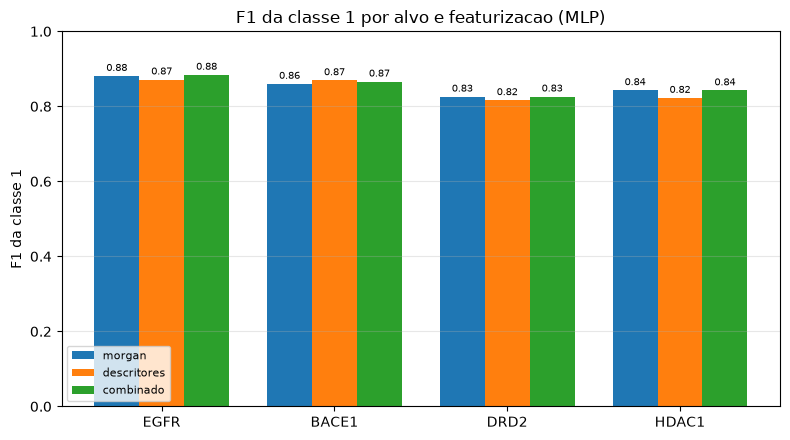

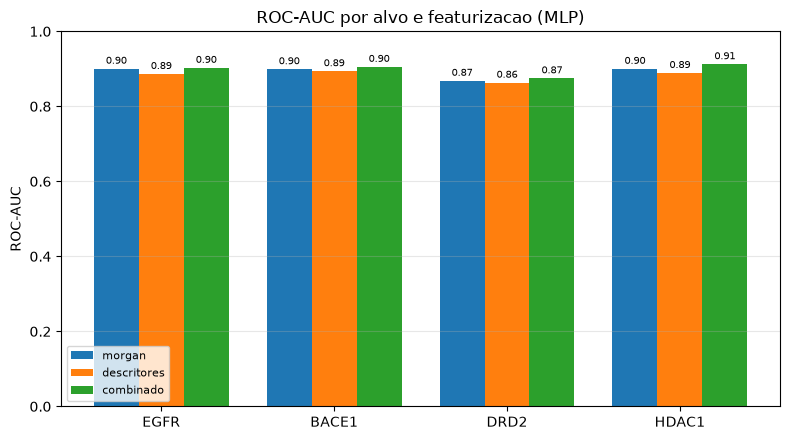

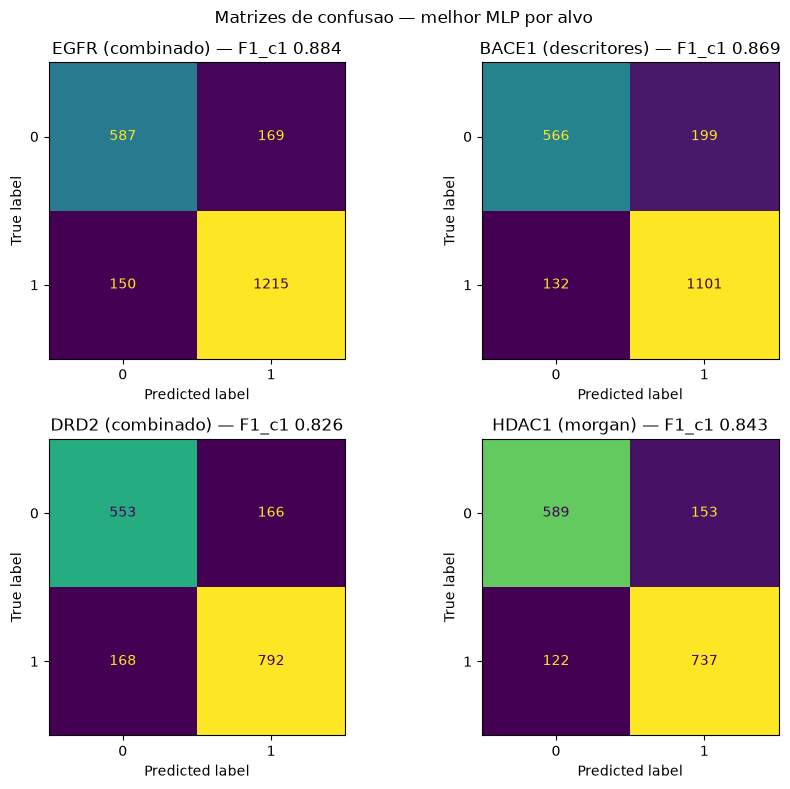

In [27]:
# melhor featurizacao por alvo (pelo F1 da classe 1 no teste)
melhor_por_alvo = (comparacao.sort_values('F1_c1', ascending=False)
                   .groupby('Alvo', as_index=False).first())
melhor_por_alvo.to_csv(PASTA_EXECUCAO / 'melhor_por_alvo.csv', index=False)
print('Melhor configuracao por alvo:')
display(melhor_por_alvo[['Alvo', 'Featurizacao', 'F1_c1', 'F1_macro',
                         'ROC_AUC', 'Acuracia']].round(4))

# 1) F1 da classe 1 por alvo x featurizacao
piv = comparacao.pivot(index='Alvo', columns='Featurizacao', values='F1_c1')
piv = piv.reindex(index=ALVOS, columns=FEATURIZACOES)
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(ALVOS)); larg = 0.26
for i, feat in enumerate(FEATURIZACOES):
    b = ax.bar(x + (i - 1) * larg, piv[feat].values, larg, label=feat)
    ax.bar_label(b, fmt='%.2f', fontsize=7, padding=2)
ax.set_xticks(x); ax.set_xticklabels(ALVOS)
ax.set_ylabel('F1 da classe 1'); ax.set_ylim(0, 1)
ax.set_title('F1 da classe 1 por alvo e featurizacao (MLP)')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
fig.tight_layout(); salva_fig(fig, 'f1_por_alvo_featurizacao.png'); plt.show()

# 2) ROC-AUC por alvo x featurizacao
piv_auc = comparacao.pivot(index='Alvo', columns='Featurizacao', values='ROC_AUC')
piv_auc = piv_auc.reindex(index=ALVOS, columns=FEATURIZACOES)
fig, ax = plt.subplots(figsize=(8, 4.5))
for i, feat in enumerate(FEATURIZACOES):
    b = ax.bar(x + (i - 1) * larg, piv_auc[feat].values, larg, label=feat)
    ax.bar_label(b, fmt='%.2f', fontsize=7, padding=2)
ax.set_xticks(x); ax.set_xticklabels(ALVOS)
ax.set_ylabel('ROC-AUC'); ax.set_ylim(0, 1)
ax.set_title('ROC-AUC por alvo e featurizacao (MLP)')
ax.legend(fontsize=8); ax.grid(axis='y', alpha=0.3)
fig.tight_layout(); salva_fig(fig, 'roc_auc_por_alvo_featurizacao.png'); plt.show()

# 3) matrizes de confusao da melhor configuracao de cada alvo
fig, eixos = plt.subplots(2, 2, figsize=(9, 8))
for ax, alvo in zip(eixos.ravel(), ALVOS):
    r = melhor_por_alvo[melhor_por_alvo['Alvo'] == alvo].iloc[0]
    feat = r['Featurizacao']
    itr, ite = SPLITS[alvo]
    y = dados_alvo[alvo]['y'].values
    X, _ = matriz(alvo, feat, FEATS_CACHE)
    pred = melhores[(alvo, feat)].predict(X[ite])
    ConfusionMatrixDisplay.from_predictions(y[ite], pred, ax=ax, colorbar=False)
    ax.set_title(f'{alvo} ({feat}) — F1_c1 {r["F1_c1"]:.3f}')
fig.suptitle('Matrizes de confusao — melhor MLP por alvo', fontsize=12)
fig.tight_layout(); salva_fig(fig, 'matrizes_confusao_melhor_por_alvo.png'); plt.show()

## Exportar resultados

Salva as tabelas, as figuras e os melhores hiperparâmetros; empacota tudo em um ZIP e registra como artefato no MLflow.

In [28]:
# melhores hiperparametros de cada (alvo, featurizacao)
parametros = {}
for (alvo, feat), busca in melhores.items():
    parametros[f'{alvo}__{feat}'] = {
        'f1_cv': round(float(busca.best_score_), 4),
        **{k.replace('mlp__', ''): str(v) for k, v in busca.best_params_.items()},
    }
with open(PASTA_EXECUCAO / 'melhores_hiperparametros_mlp.json', 'w', encoding='utf-8') as f:
    json.dump(parametros, f, ensure_ascii=False, indent=2)

arquivos = sorted(str(p) for p in PASTA_EXECUCAO.glob('*')
                  if p.suffix in {'.csv', '.png', '.json'})
zip_path = PASTA_EXECUCAO / 'resultados_redes_neurais.zip'
with zipfile.ZipFile(zip_path, 'w') as z:
    for a in arquivos:
        z.write(a, arcname=Path(a).name)

with mlflow.start_run(run_name='relatorio_artefatos'):
    for a in arquivos + [str(zip_path)]:
        mlflow.log_artifact(a)
    mlflow.log_param('pasta_execucao', str(PASTA_EXECUCAO))
    mlflow.log_param('modo', MODO)
    mlflow.log_metric('n_arquivos', len(arquivos))

print('Pasta da execucao:', PASTA_EXECUCAO)
print('Arquivos:', ', '.join(Path(a).name for a in arquivos))

Pasta da execucao: /Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/docs/redes_neurais/resultados/execucao_20261109_101057
Arquivos: baseline_por_alvo.csv, comparacao_featurizacoes.csv, distribuicao_pchembl.png, efeito_escala.csv, f1_por_alvo_featurizacao.png, limpeza_por_alvo.csv, matrizes_confusao_melhor_por_alvo.png, melhor_por_alvo.csv, melhores_hiperparametros_mlp.json, politica_medida.csv, roc_auc_por_alvo_featurizacao.png, sensibilidade_limiar.csv


## Consultar e comparar no MLflow

Exporta as runs do experimento para CSV e mostra como abrir a interface.

In [29]:
print('Tracking URI:', mlflow.get_tracking_uri())
print('Experimento:', EXPERIMENTO)

runs = mlflow.search_runs(experiment_names=[EXPERIMENTO])
print('Runs registradas:', len(runs))
runs.to_csv(PASTA_DOCS / 'mlflow_runs_redes_neurais.csv', index=False)

colunas = [c for c in ['tags.mlflow.runName', 'metrics.f1_cv', 'metrics.F1_c1',
                       'metrics.F1_macro', 'metrics.ROC_AUC', 'metrics.FN']
           if c in runs.columns]
display(runs[runs['tags.mlflow.runName'].str.startswith('mlp_', na=False)][colunas]
        .sort_values('metrics.F1_c1', ascending=False).round(4).reset_index(drop=True))

print('\nPara abrir a interface do MLflow, no terminal, na raiz do projeto:')
print('  mlflow ui --backend-store-uri sqlite:///mlflow.db')
print('Depois acesse http://127.0.0.1:5000 e selecione o experimento', EXPERIMENTO)

Tracking URI: sqlite:////Users/diegocordeirodeoliveira/Documents/mestrado/ufpi2025/Disciplinas/Aprendizado de máquina/trabalho/mlflow.db
Experimento: chembl_redes_neurais
Runs registradas: 86


,tags.mlflow.runName,metrics.f1_cv,metrics.F1_c1,metrics.F1_macro,metrics.ROC_AUC,metrics.FN
0,mlp_EGFR_combinado,0.8843,0.8840,0.8351,0.9023,150.0
1,mlp_EGFR_combinado,0.8843,0.8840,0.8351,0.9023,150.0
2,mlp_EGFR_morgan,0.8816,0.8808,0.8244,0.9000,131.0
3,mlp_EGFR_morgan,0.8816,0.8808,0.8244,0.9000,131.0
4,mlp_EGFR_descritores,0.8698,0.8737,0.8128,0.8829,137.0
5,mlp_EGFR_descritores,0.8725,0.8713,0.8079,0.8860,136.0
6,mlp_BACE1_combinado,0.8688,0.8710,0.8282,0.9048,146.0
7,mlp_BACE1_descritores,0.8632,0.8693,0.8215,0.8934,132.0
8,mlp_BACE1_combinado,0.8714,0.8657,0.8213,0.9049,153.0
9,mlp_BACE1_descritores,0.8594,0.8632,0.8155,0.8825,148.0



Para abrir a interface do MLflow, no terminal, na raiz do projeto:
  mlflow ui --backend-store-uri sqlite:///mlflow.db
Depois acesse http://127.0.0.1:5000 e selecione o experimento chembl_redes_neurais
